## Importing the libraries

In [150]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## Importing the Datasets

In [208]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

## Exploratory Data Analysis

In [209]:
train_df.shape

(891, 12)

In [210]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [211]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Which columns have missing values, and how many in each?

In [212]:
train_df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

### What percentage of each column is missing?

In [213]:
(train_df.isna().sum()/len(train_df)) * 100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

### Which column is so sparse you would probably not use it directly?

### For Age, what would be a reasonable way to fill the gaps, and why? You can write this down and not apply it yet.

### Could the data be missing for a reason, for example that missing Cabin is related to class?

In [214]:
train_df.groupby(["Pclass"])["Cabin"].value_counts()

Pclass  Cabin      
1       B96 B98        4
        C23 C25 C27    4
        C22 C26        3
        B18            2
        B20            2
                      ..
3       F G73          2
        E10            1
        F E69          1
        F G63          1
        F38            1
Name: count, Length: 147, dtype: int64

### What is the overall survival rate?

In [215]:
train_df["Survived"].mean()

np.float64(0.3838383838383838)

### How does survival differ by sex? By passenger class? By port of embarkation?

In [216]:
train_df.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [217]:
train_df.groupby("Pclass")["Survived"].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [218]:
train_df.groupby("Embarked")["Survived"].mean()

Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64

### How does survival differ across age groups? You’ll need to decide the bins yourself.

In [219]:
train_df["Agegroup"] = pd.cut(x = train_df["Age"], bins = [0, 12, 18, 35, 60, 100], labels=["0-12", "13-18", "19-35", "36-60", "60+"])

In [220]:
train_df["Agegroup"].value_counts()

Agegroup
19-35    358
36-60    195
13-18     70
0-12      69
60+       22
Name: count, dtype: int64

### Does survival change with family size (SibSp + Parch + 1)?

In [221]:
train_df["FamilySize"] = train_df["SibSp"] + train_df["Parch"] + 1

In [222]:
train_df.groupby("FamilySize")["Survived"].mean()

FamilySize
1     0.303538
2     0.552795
3     0.578431
4     0.724138
5     0.200000
6     0.136364
7     0.333333
8     0.000000
11    0.000000
Name: Survived, dtype: float64

### Within each class, does the gap between men and women stay the same?

In [223]:
train_df.groupby("Pclass")["Sex"].value_counts()

Pclass  Sex   
1       male      122
        female     94
2       male      108
        female     76
3       male      347
        female    144
Name: count, dtype: int64

In [224]:
male = train_df.groupby("Pclass")["Sex"].value_counts().loc[(1, "male")]
female = train_df.groupby("Pclass")["Sex"].value_counts().loc[(1, "female")]

In [225]:
train_df.groupby("Pclass")["Sex"].value_counts().unstack()

Sex,female,male
Pclass,,
1,94,122
2,76,108
3,144,347


### Which group had the highest survival rate, and which had the lowest?

## Visualizations

### How much of each column is missing?

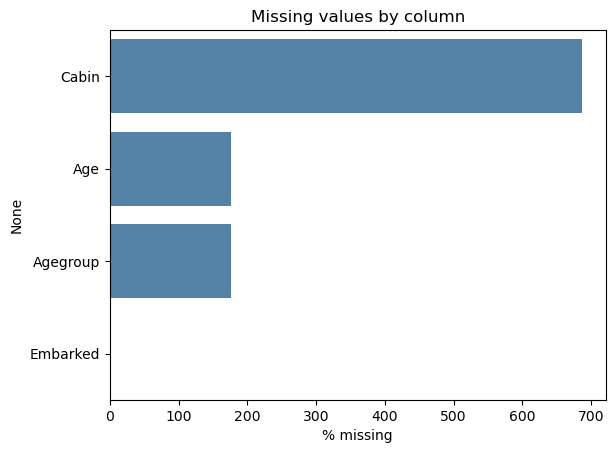

In [226]:
null_values = train_df.isna().sum()
m = null_values[null_values>0].sort_values(ascending=False)
sns.barplot(x = m.values, y = m.index, color="steelblue")
plt.xlabel("% missing")
plt.title("Missing values by column")
plt.show()

### How does survival rate differ by sex?

Text(0.5, 1.0, 'Survival by Sex')

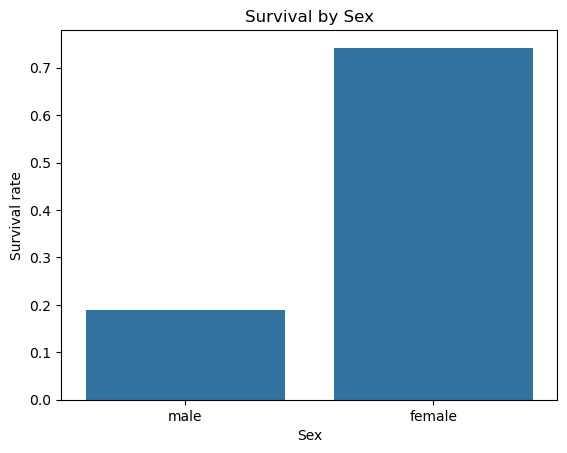

In [227]:
sns.barplot(data = train_df, x="Sex", y="Survived", errorbar=None)
plt.ylabel("Survival rate")
plt.title("Survival by Sex")

### How does survival rate differ by class and sex together?

Text(0.5, 1.0, 'Survival by Sex and Class')

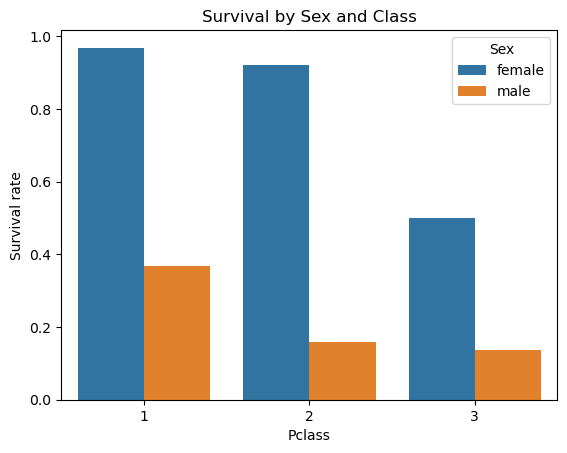

In [228]:
sns.barplot(data = train_df, x="Pclass", y="Survived", hue="Sex", errorbar=None)
plt.ylabel("Survival rate")
plt.title("Survival by Sex and Class")

### How does the age distribution differ between survivors and non-survivors?

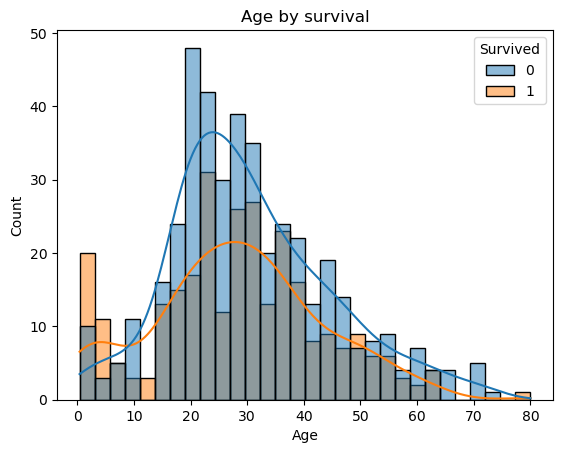

In [229]:
sns.histplot(data=train_df.dropna(subset=["Age"]), x="Age", hue="Survived", bins=30, kde=True)
plt.title("Age by survival")
plt.show()

### How does survival rate change with family size?

Text(0.5, 1.0, 'Survival by FamilySize')

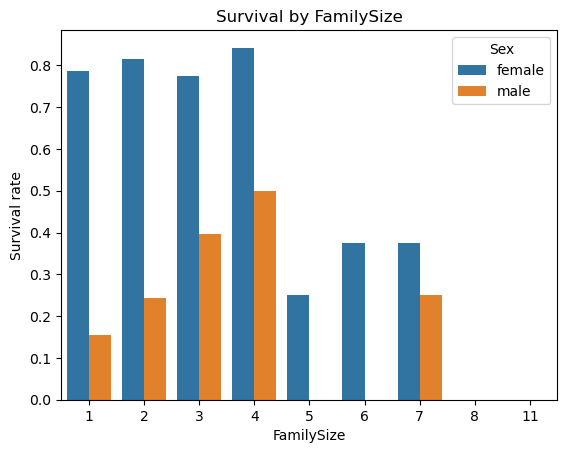

In [230]:
sns.barplot(x=train_df["FamilySize"], y=train_df["Survived"], hue=train_df["Sex"], errorbar=None)
plt.ylabel("Survival rate")
plt.title("Survival by FamilySize")

## Data Cleaning

## Creating Validation Set

In [231]:
X = train_df.drop(columns=["Survived", "Agegroup"])
Y = train_df["Survived"]

In [232]:
X_Train, X_Val, Y_Train, Y_Val = train_test_split(X, Y, test_size=0.20, random_state = 42, stratify = Y)

In [233]:
X_Train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 692 to 507
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  712 non-null    int64  
 1   Pclass       712 non-null    int64  
 2   Name         712 non-null    object 
 3   Sex          712 non-null    object 
 4   Age          575 non-null    float64
 5   SibSp        712 non-null    int64  
 6   Parch        712 non-null    int64  
 7   Ticket       712 non-null    object 
 8   Fare         712 non-null    float64
 9   Cabin        160 non-null    object 
 10  Embarked     710 non-null    object 
 11  FamilySize   712 non-null    int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 72.3+ KB


In [234]:
X_Train.head(1)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize
692,693,3,"Lam, Mr. Ali",male,NaN,0,0,1601,56.4958,NaN,S,1


In [235]:
names = X_Train["Name"].apply(lambda x: x.split(","))

In [236]:
names

692                                     [Lam,  Mr. Ali]
481                 [Frost,  Mr. Anthony Wood "Archie"]
527                               [Farthing,  Mr. John]
855                       [Aks,  Mrs. Sam (Leah Rosen)]
801      [Collyer,  Mrs. Harvey (Charlotte Annie Tate)]
                             ...                       
359                [Mockler,  Miss. Helen Mary "Ellie"]
258                                 [Ward,  Miss. Anna]
736          [Ford,  Mrs. Edward (Margaret Ann Watson)]
462                                [Gee,  Mr. Arthur H]
507    [Bradley,  Mr. George ("George Arthur Brayton")]
Name: Name, Length: 712, dtype: object

In [237]:
for df in [X_Train, X_Val]:
    titles = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
    titles.replace({"Ms": "Miss", "Mme": "Mrs", "Mlle": "Miss"})
    common = ["Mr", "Miss", "Mrs", "Master"]
    df["title"] = titles.where(titles.isin(common), "Rare")

    df["isalone"] = (df["FamilySize"]==1).astype(int)
    df["hasCabin"] = df["Cabin"].notna().astype(int)
    
    df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"], inplace=True)

In [241]:
X_Train.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,title,isalone,hasCabin
692,3,male,NaN,0,0,56.4958,S,1,Mr,1,0
481,2,male,NaN,0,0,0.0000,S,1,Mr,1,0
527,1,male,NaN,0,0,221.7792,S,1,Mr,1,1
855,3,female,18.0,0,1,9.3500,S,2,Mrs,0,0
801,2,female,31.0,1,1,26.2500,S,3,Mrs,0,0


In [247]:
age_medians = X_Train.groupby(["Pclass", "Sex"])["Age"].median()
mapped_train = pd.Series(X_Train.set_index(["Pclass", "Sex"]).index.map(age_medians), index=X_Train.index)
X_Train["Age"] = X_Train["Age"].fillna(mapped_train)
mapped_val = pd.Series(X_Val.set_index(["Pclass", "Sex"]).index.map(age_medians), index=X_Val.index)
X_Val["Age"] = X_Val["Age"].fillna(mapped_val)

In [248]:
X_Train.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,title,isalone,hasCabin
692,3,male,26.0,0,0,56.4958,S,1,Mr,1,0
481,2,male,30.0,0,0,0.0000,S,1,Mr,1,0
527,1,male,40.0,0,0,221.7792,S,1,Mr,1,1
855,3,female,18.0,0,1,9.3500,S,2,Mrs,0,0
801,2,female,31.0,1,1,26.2500,S,3,Mrs,0,0


In [249]:
embarked_mode = X_Train["Embarked"].mode()[0]
X_Train["Embarked"] = X_Train["Embarked"].fillna(embarked_mode)
X_Val["Embarked"] = X_Val["Embarked"].fillna(embarked_mode)

In [250]:
X_Train["Agegroup"] = pd.cut(x = X_Train["Age"], bins = [0, 12, 18, 35, 60, 100], labels=["0-12", "13-18", "19-35", "36-60", "60+"])
X_Val["Agegroup"] = pd.cut(x = X_Val["Age"], bins = [0, 12, 18, 35, 60, 100], labels=["0-12", "13-18", "19-35", "36-60", "60+"])

## Model Training

In [251]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics  import accuracy_score, classification_report

In [256]:
scale = ["Sex", "Embarked", "title", "Pclass", "Agegroup"]
X_Train["Pclass"] = X_Train["Pclass"].astype(str)  # so get_dummies treats it as a category
X_Val["Pclass"] = X_Val["Pclass"].astype(str) 
X_Train = pd.get_dummies(X_Train, columns=scale, drop_first=True)
X_Val = pd.get_dummies(X_Val, columns=scale, drop_first=True)

In [255]:
num = ["Fare", "FamilySize"]
scaler = StandardScaler()
X_Train[num] = scaler.fit_transform(X_Train[num])
X_Val[num] = scaler.fit(X_Val[num])

In [259]:
X_Val = X_Val.reindex(columns = X_Train.columns, fill_value=0)

In [260]:
X_Train.head(1)

,SibSp,Parch,Fare,FamilySize,isalone,hasCabin,Sex_male,Embarked_Q,Embarked_S,title_Miss,title_Mr,title_Mrs,title_Rare,Pclass_2,Pclass_3,Agegroup_13-18,Agegroup_19-35,Agegroup_36-60,Agegroup_60+
692,0,0,0.513812,-0.556339,1,0,True,False,True,False,True,False,False,False,True,False,True,False,False


In [261]:
X_Val.head(1)

,SibSp,Parch,Fare,FamilySize,isalone,hasCabin,Sex_male,Embarked_Q,Embarked_S,title_Miss,title_Mr,title_Mrs,title_Rare,Pclass_2,Pclass_3,Agegroup_13-18,Agegroup_19-35,Agegroup_36-60,Agegroup_60+
565,2,0,-0.172088,0.59328,0,0,True,False,True,False,True,False,False,False,True,False,True,False,False


In [262]:
model = LogisticRegression(max_iter = 200)
model.fit(X_Train, Y_Train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [263]:
y_train_pred = model.predict(X_Train)
y_val_pred = model.predict(X_Val)

train_acc = accuracy_score(Y_Train, y_train_pred)
val_acc = accuracy_score(Y_Val, y_val_pred)

print(f"Training Accuracy:   {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")

Training Accuracy:   0.8371
Validation Accuracy: 0.8101


## Extra

In [265]:
!pip install xgboost
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.3 MB/s eta 0:00:39
    --------------------------------------- 0.8/48.9 MB 1.6 MB/s eta 0:00:31
    --------------------------------------- 1.0/48.9 MB 1.4 MB/s eta 0:00:35
   - -------------------------------------- 1.8/48.9 MB 1.9 MB/s eta 0:00:26
   - -------------------------------------- 2.4/48.9 MB 2.1 MB/s eta 0:00:23
   -- ------------------------------------- 3.1/48.9 MB 2.3 MB/s eta 0:00:20
   --- ------------------------------------ 3.9/48.9 MB 2.5 MB/s eta 0:00:18
   --- ------------------------------------ 4.5/48.9 MB 2.6 MB/s eta 0:00:18
   ---- ----------------------------------- 5.0/48.9 MB 2.6 MB/s eta 0:00:17
   ---- ----------------------------------- 5.8/48.9 MB 2.6 MB/s eta 0:00:17
   ----- -----------

In [266]:
X_Train = X_Train.astype({col: "int" for col in X_Train.select_dtypes("bool").columns})
X_Val = X_Val.astype({col: "int" for col in X_Val.select_dtypes("bool").columns})

In [268]:
cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

rf_model = RandomForestClassifier(n_estimators=150, max_depth=6, min_samples_leaf=3, random_state=42)

xgb_model = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05, eval_metric="logloss", random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

rf_cv = cross_validate(
    rf_model, X_Train, Y_Train, cv=cv, scoring=scoring, n_jobs=-1
)

xgb_cv = cross_validate(xgb_model, X_Train, Y_Train, cv=cv, scoring=scoring, n_jobs=-1)

In [270]:
results = []
models_cv = {"Random Forest": rf_cv, "XGBoost": xgb_cv}

for model_name, cv_scores in models_cv.items():
    row = {"Model": model_name}
    for metric in scoring.keys():
        scores = cv_scores[f"test_{metric}"]
        row[metric.capitalize()] = f"{scores.mean():.4f} ± {scores.std():.4f}"
    results.append(row)

comparison_df = pd.DataFrame(results).set_index("Model")
display(comparison_df)

,Accuracy,Precision,Recall,F1,Roc_auc
Model,,,,,
Random Forest,0.8174 ± 0.0143,0.8088 ± 0.0347,0.6886 ± 0.0327,0.7429 ± 0.0204,0.8741 ± 0.0223
XGBoost,0.8301 ± 0.0210,0.8108 ± 0.0515,0.7327 ± 0.0266,0.7683 ± 0.0215,0.8964 ± 0.0238


In [271]:
rf_model.fit(X_Train, Y_Train)
xgb_model.fit(X_Train, Y_Train)

print(f"Logistic Regression Val Acc : {val_acc:.4f}")
print(f"Random Forest Val Acc       : {rf_model.score(X_Val, Y_Val):.4f}")
print(f"XGBoost Val Acc             : {xgb_model.score(X_Val, Y_Val):.4f}")

Logistic Regression Val Acc : 0.8101
Random Forest Val Acc       : 0.8156
XGBoost Val Acc             : 0.8101


In [272]:
importance_df = pd.DataFrame({
    "Feature": X_Train.columns,
    "Random Forest": rf_model.feature_importances_,
    "XGBoost": xgb_model.feature_importances_,
}).sort_values(by="Random Forest", ascending=False)

display(importance_df)

,Feature,Random Forest,XGBoost
6,Sex_male,0.253019,0.018607
10,title_Mr,0.186480,0.426729
2,Fare,0.125246,0.025929
5,hasCabin,0.070653,0.063073
14,Pclass_3,0.070393,0.173183
11,title_Mrs,0.056365,0.013354
9,title_Miss,0.054356,0.004415
3,FamilySize,0.048508,0.048585
0,SibSp,0.028889,0.020024
1,Parch,0.021415,0.018516


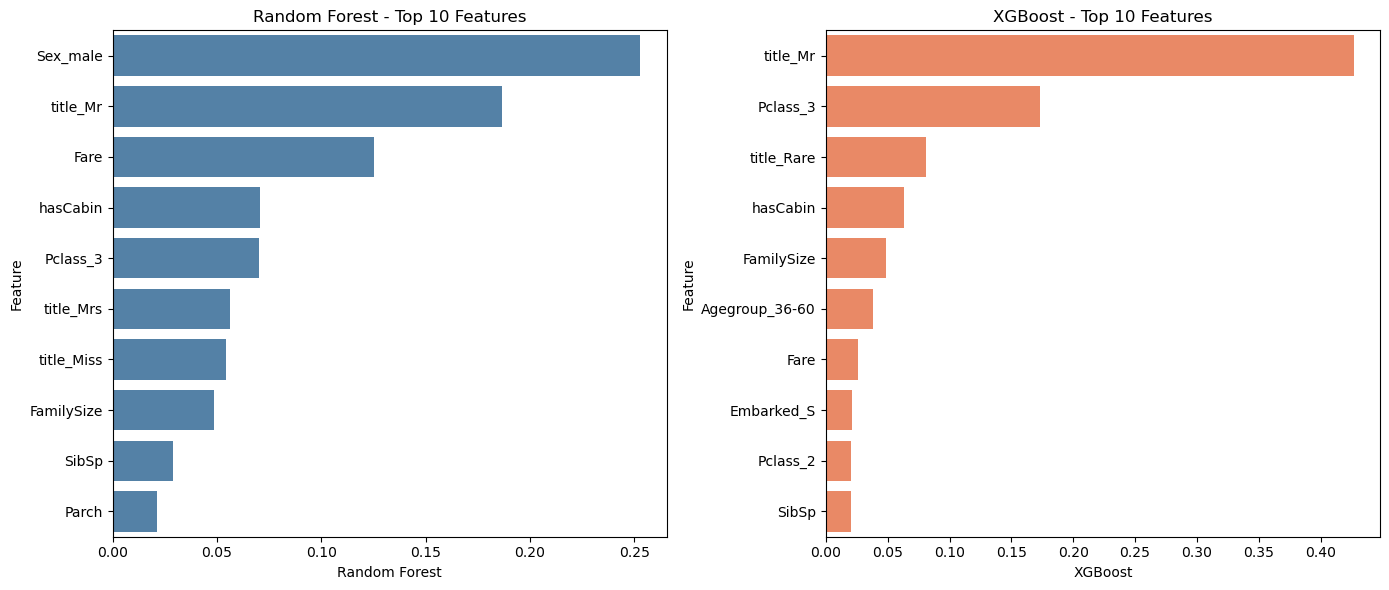

In [273]:
# Plot top 10 features
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Random Forest",
    y="Feature",
    ax=axes[0],
    color="steelblue",
)
axes[0].set_title("Random Forest - Top 10 Features")

sns.barplot(
    data=importance_df.sort_values(by="XGBoost", ascending=False).head(10),
    x="XGBoost",
    y="Feature",
    ax=axes[1],
    color="coral",
)
axes[1].set_title("XGBoost - Top 10 Features")

plt.tight_layout()
plt.show()